# 05. Advanced Analytics, Risk Modeling and Intelligence Layer
Implementation of Historical and Parametric Value at Risk (VaR), cohort retention, K-Means investor segmentation, 10,000-path Monte Carlo simulations, and Markowitz Efficient Frontier optimization.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path('..').resolve()))
from scripts.recommender import calculate_value_at_risk, calculate_monthly_cohort_retention, InvestorSegmenter, recommend_funds
from scripts.compute_metrics import run_monte_carlo_simulation, optimize_markowitz_portfolio

proc_dir = Path('../data/processed')
df_nav = pd.read_csv(proc_dir / 'fact_nav.csv')
df_txn = pd.read_csv(proc_dir / 'fact_transactions.csv')
df_perf = pd.read_csv(proc_dir / 'fact_performance.csv')


## 95% and 99% Value at Risk Analysis
Empirical and parametric downside capital-at-risk estimation across top equity schemes.


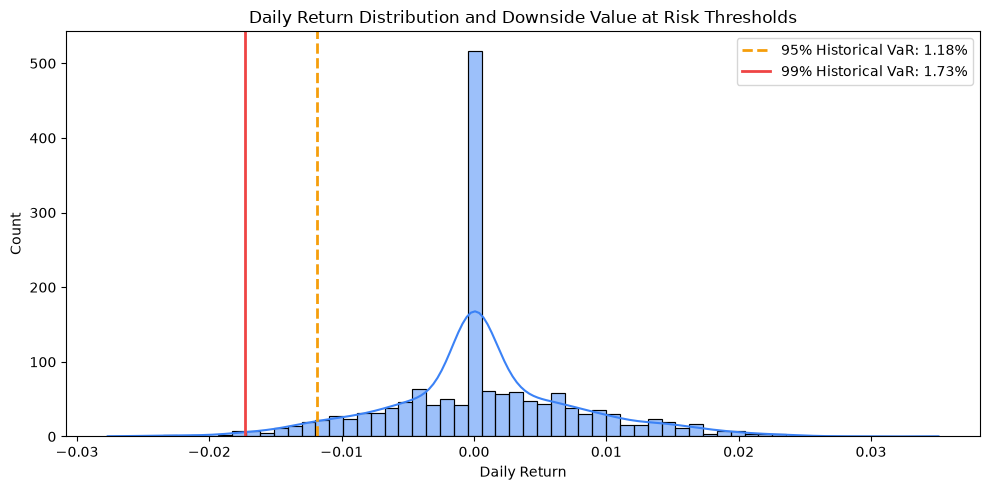

In [2]:
sample_amfi = df_perf['amfi_code'].iloc[0]
sample_nav = df_nav[df_nav['amfi_code'] == sample_amfi].sort_values('nav_date')['nav']
sample_returns = sample_nav.pct_change().dropna()

var_95 = calculate_value_at_risk(sample_returns, confidence_level=0.95)
var_99 = calculate_value_at_risk(sample_returns, confidence_level=0.99)

plt.figure(figsize=(10, 5))
sns.histplot(sample_returns, bins=60, kde=True, color='#3B82F6')
plt.axvline(-var_95['historical_var'], color='#F59E0B', linestyle='--', linewidth=2, label=f"95% Historical VaR: {var_95['historical_var']*100:.2f}%")
plt.axvline(-var_99['historical_var'], color='#EF4444', linestyle='-', linewidth=2, label=f"99% Historical VaR: {var_99['historical_var']*100:.2f}%")
plt.title('Daily Return Distribution and Downside Value at Risk Thresholds')
plt.xlabel('Daily Return')
plt.legend()
plt.tight_layout()
plt.show()


## Monthly Investor Retention Cohort Matrix
Tracking investor longevity and ongoing platform participation across monthly acquisition cohorts.


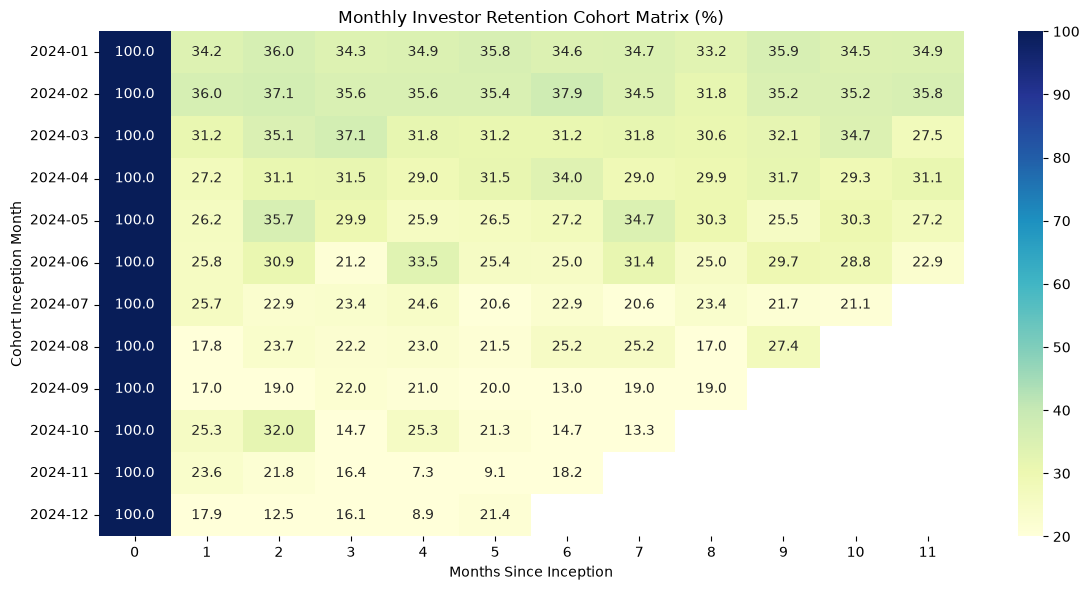

In [3]:
cohort_matrix = calculate_monthly_cohort_retention(df_txn)

plt.figure(figsize=(12, 6))
sns.heatmap(cohort_matrix.iloc[:12, :12], cmap='YlGnBu', annot=True, fmt='.1f', vmin=20, vmax=100)
plt.title('Monthly Investor Retention Cohort Matrix (%)')
plt.ylabel('Cohort Inception Month')
plt.xlabel('Months Since Inception')
plt.tight_layout()
plt.show()


## Behavioral Investor Segmentation: K-Means Clustering
Segmenting 5,000 distinct investors into Moderate Retail, Affluent HNI, and Emerging Youth cohorts.


2026-10-31 11:07:21,586 - Recommender_Engine - INFO - Successfully loaded ML models (Scaler & KMeans).


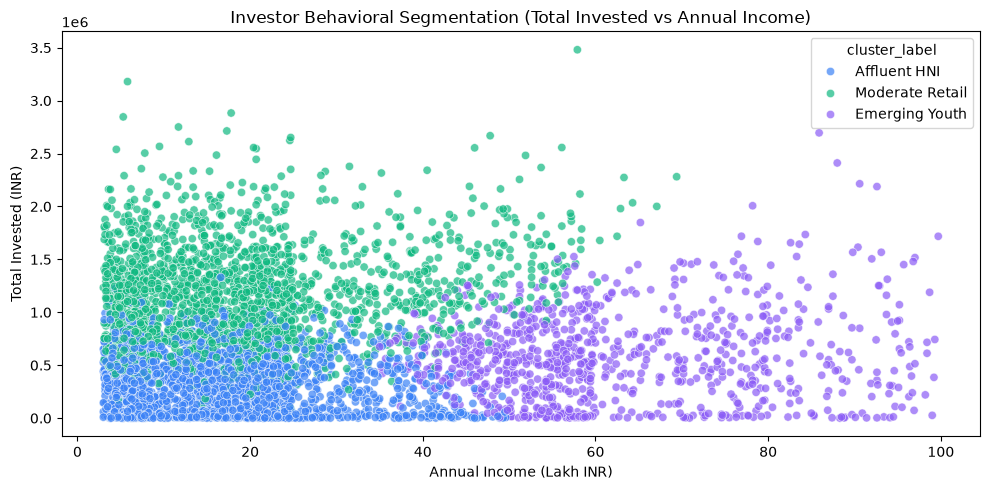

In [4]:
segmenter = InvestorSegmenter(models_dir=Path('../data/processed'))
df_clustered = pd.read_csv(proc_dir / 'clustered_investors.csv')

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_clustered,
    x='annual_income',
    y='total_invested',
    hue='cluster_label',
    palette=['#3B82F6', '#10B981', '#8B5CF6'],
    alpha=0.7
)
plt.title('Investor Behavioral Segmentation (Total Invested vs Annual Income)')
plt.xlabel('Annual Income (Lakh INR)')
plt.ylabel('Total Invested (INR)')
plt.tight_layout()
plt.show()


## Five-Year 10,000-Path Monte Carlo NAV Simulation
Projecting future asset valuation envelopes using Geometric Brownian Motion stochastic drift and diffusion.


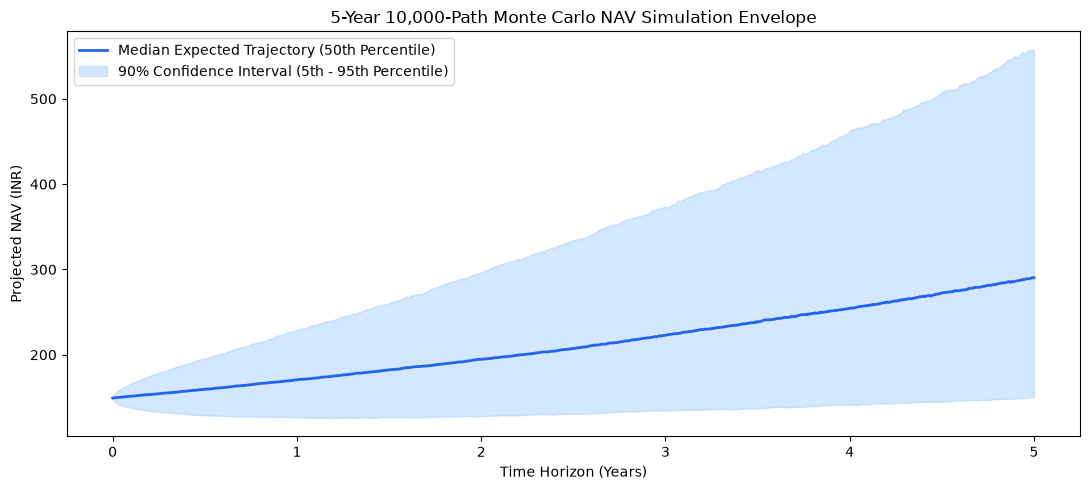

In [5]:
first_nav = float(sample_nav.iloc[-1])
mc_res = run_monte_carlo_simulation(initial_nav=first_nav, mu=0.15, sigma=0.18, n_years=5, n_paths=10000)

plt.figure(figsize=(11, 5))
time_axis = np.linspace(0, 5, mc_res['n_steps'] + 1)
plt.plot(time_axis, mc_res['percentile_50_curve'], color='#2563EB', linewidth=2, label='Median Expected Trajectory (50th Percentile)')
plt.fill_between(time_axis, mc_res['percentile_5_curve'], mc_res['percentile_95_curve'], color='#93C5FD', alpha=0.4, label='90% Confidence Interval (5th - 95th Percentile)')
plt.title('5-Year 10,000-Path Monte Carlo NAV Simulation Envelope')
plt.xlabel('Time Horizon (Years)')
plt.ylabel('Projected NAV (INR)')
plt.legend()
plt.tight_layout()
plt.show()


## Markowitz Modern Portfolio Theory: Efficient Frontier Optimization
Solving for optimal portfolio weights across five distinct mutual fund assets.


In [6]:
top_5_amfi = df_perf['amfi_code'].head(5).tolist()
pivot_nav = df_nav[df_nav['amfi_code'].isin(top_5_amfi)].pivot(index='nav_date', columns='amfi_code', values='nav')
daily_ret = pivot_nav.pct_change().dropna()

mpt_res = optimize_markowitz_portfolio(daily_ret)
print('Optimal Maximum Sharpe Portfolio Weights:')
for asset, w in mpt_res['max_sharpe']['weights'].items():
    print(f'  Scheme {asset}: {w*100:.2f}%')
print(f'Max Sharpe Ratio: {mpt_res["max_sharpe"]["sharpe_ratio"]:.2f}')


Optimal Maximum Sharpe Portfolio Weights:
  Scheme 119120: 0.00%
  Scheme 119551: 45.73%
  Scheme 119552: 34.21%
  Scheme 119598: 20.06%
  Scheme 119599: 0.00%
Max Sharpe Ratio: 1.52


## Multi-Factor Recommendation Engine Execution
Matching investor personas with personalized, risk-aligned mutual fund schemes.


In [7]:
sample_investor = {'total_invested': 2500000.0, 'txn_count': 18, 'annual_income': 45.0}
persona = segmenter.predict_cluster(sample_investor)
recs = recommend_funds(persona, df_perf, top_n=5)
recs


,amfi_code,scheme_name,category,fund_house,return_3yr_pct,sharpe_ratio,alpha,expense_ratio_pct,composite_score
9,100025,HDFC Short Term Debt Fund - Regular - Growth,Short Duration,HDFC Mutual Fund,7.37,1.84,1.98,0.56,11.200
14,120507,ICICI Pru Liquid Fund - Regular - Growth,Liquid,ICICI Prudential MF,7.68,7.68,1.85,0.74,11.250
3,119599,SBI Small Cap Fund - Direct Plan - Growth,Small Cap,SBI Mutual Fund,23.14,0.93,1.13,0.72,11.925
23,120844,Kotak Liquid Fund - Regular - Growth,Liquid,Kotak Mahindra MF,6.18,6.18,1.52,0.60,12.200
22,120843,Kotak Flexicap Fund - Regular - Growth,Flexi Cap,Kotak Mahindra MF,15.65,0.98,1.85,1.45,13.400
